# CNN + MLP cho FER2013
Chuyển mẫu `2. CNN + MLP/1_MNIST_CNN.ipynb` từ Keras sang PyTorch theo yêu cầu Emotion Recognition.
Đây là bản áp dụng cho FER2013, không huấn luyện chữ số MNIST: ảnh xám 48×48, 7 cảm xúc.
Notebook này đã gắn run thực `EXP002_CNN_MLP/20261120_153239_715338`. Chạy lần lượt các ô để xem kiến trúc, lịch sử huấn luyện, kết quả test và filter.

In [1]:
import json
import sys
from pathlib import Path
import pandas as pd
import torch
from IPython.display import Image, display

project = next(p for p in (Path.cwd(), *Path.cwd().parents)
               if (p / "configs/cnn_mlp.yaml").is_file())
if str(project) not in sys.path:
    sys.path.insert(0, str(project))
from models import build_model
from train import run_experiment
from evaluate import evaluate_checkpoint
from training_utils import select_device, seed_everything
seed_everything(42)

## 1 Dữ liệu
Đặt `train.csv` và `test.csv` vào `BTL02/data/`. Cần cột `pixels` (2304 số 0–255), nhãn `emotion` (0–6).
Nếu test thiếu nhãn, cần thêm `fer2013.csv`; chương trình kiểm tra pixel và thứ tự trước khi gán nhãn.
Thứ tự: Angry, Disgust, Fear, Happy, Sad, Surprise, Neutral.
Chia train/validation phân tầng 80/20 với seed chia tập 42, pixel /255; giữ nguyên quy tắc baseline.
Augmentation (nếu bật) chỉ cho train. Validation dùng chọn checkpoint; test chỉ đánh giá sau khi chốt cấu hình.

## 2 Kiến trúc từ mẫu MNIST
| Bước | Đầu ra |
|---|---|
| Input | N × 1 × 48 × 48 |
| Conv 64, ReLU, Pool, Dropout 0.2 | N × 64 × 24 × 24 |
| Conv 128, ReLU, Pool, Dropout 0.2 | N × 128 × 12 × 12 |
| Conv 256, ReLU, Pool, Dropout 0.2 | N × 256 × 6 × 6 |
| Flatten | N × 9216 |
| Linear 512, ReLU, Dropout 0.2 | N × 512 |
| Linear 512, ReLU, Dropout 0.2 | N × 512 |
| Linear 7 | N × 7 logits |

Giữ 3 khối CNN và 2 lớp ẩn MLP như mẫu. PyTorch dùng NCHW và `CrossEntropyLoss` với nhãn long;
không one-hot hoặc Softmax trước loss. Softmax chỉ cần khi hiển thị xác suất.

In [2]:
model = build_model("cnn_mlp").eval()
print(model)
with torch.inference_mode():
    logits = model(torch.zeros(2, 1, 48, 48))
assert logits.shape == (2, 7)
print("Output:", tuple(logits.shape))
print("Parameters:", sum(p.numel() for p in model.parameters()))

CNNMLP(
  (features): Sequential(
    (0): Conv2d(1, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Dropout(p=0.2, inplace=False)
    (4): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): ReLU()
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Dropout(p=0.2, inplace=False)
    (8): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): ReLU()
    (10): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (11): Dropout(p=0.2, inplace=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=9216, out_features=512, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=512, out_features=512, bias=True)
    (5): ReLU()
    (6): Dropout(p=0.2, inplace=False)
    (7): Li

## 3 Huấn luyện và tiện ích dùng chung
`training_utils/` cung cấp vòng lặp, checkpoint theo val_loss, EarlyStopping, ReduceLROnPlateau và logging.
Config `configs/cnn_mlp.yaml` giữ Adam, LR 0.001, batch 64, 30 epochs như baseline.
Các tùy chọn augmentation/early stopping/scheduler mặc định tắt để so sánh kiến trúc trước.
Muốn thử tiện ích: sao chép YAML, đổi experiment và chỉ bật một yếu tố mỗi lần.
`--smoke` chạy một epoch toàn bộ train/validation, không phải một minibatch.

In [3]:
TRAIN_AGAIN = False
RUN_PATH = "results/EXP002_CNN_MLP/20261120_153239_715338"
run = project / RUN_PATH if RUN_PATH else None
if TRAIN_AGAIN:
    run = run_experiment(project / "configs/cnn_mlp.yaml")
if run is not None:
    training = json.loads((run / "training.json").read_text(encoding="utf-8"))
    history = pd.read_csv(run / "history.csv")
    display(history)
    print("Run:", run.name)
    print("Epoch tốt nhất:", training["best_epoch"])
    print("Validation loss tốt nhất:", training["best_val_loss"])
    print("Validation accuracy tại epoch tốt nhất:", training["best_val_accuracy"])
    print("Số tham số:", training["parameters"])
    print("Thiết bị:", training["device"])
else:
    print("Chưa chọn run. Bật TRAIN_AGAIN hoặc điền RUN_PATH để xem kết quả thật.")

,epoch,train_loss,train_accuracy,val_loss,val_accuracy,learning_rate
0,1,1.748724,0.281926,1.640318,0.358760,0.001
1,2,1.569140,0.384465,1.480806,0.430338,0.001
2,3,1.461754,0.435930,1.384223,0.467433,0.001
3,4,1.383672,0.462620,1.325031,0.491118,0.001
4,5,1.313744,0.498193,1.277860,0.521073,0.001
5,6,1.258011,0.520399,1.233383,0.526123,0.001
6,7,1.205392,0.540515,1.209568,0.540230,0.001
7,8,1.148450,0.564941,1.201351,0.542494,0.001
8,9,1.095159,0.584578,1.205558,0.538314,0.001
9,10,1.039429,0.606958,1.210734,0.544235,0.001


Run: 20261120_153239_715338
Epoch tốt nhất: 15
Validation loss tốt nhất: 1.1981438398361206
Validation accuracy tại epoch tốt nhất: 0.552943229675293
Số tham số: 5355015
Thiết bị: cpu


## 4 Đánh giá mô hình đã chọn
Chỉ bật `EVALUATE_FINAL` khi đã chốt cấu hình bằng validation.
Chương trình nạp best.pth, tính accuracy, macro F1, confusion matrix và vẽ kết quả.
Run mẫu dưới đây đã được đánh giá; ô tự đọc `evaluation.json` để hiển thị lại kết quả.

In [4]:
EVALUATE_FINAL = False
if EVALUATE_FINAL:
    if run is None:
        raise ValueError("Cần chọn hoặc huấn luyện một run trước.")
    import yaml
    cfg = yaml.safe_load((run / "config.yaml").read_text(encoding="utf-8"))
    result = evaluate_checkpoint(run, project / cfg["data_dir"], cfg["batch_size"],
                                 select_device(cfg.get("device", "auto")))
    print("Accuracy:", result["accuracy"], "Macro F1:", result["macro_f1"])
    display(pd.DataFrame(result["per_class"]).T)
elif run is not None and (run / "evaluation.json").is_file():
    result = json.loads((run / "evaluation.json").read_text(encoding="utf-8"))
    print("Test accuracy:", result["accuracy"])
    print("Test macro F1:", result["macro_f1"])
    display(pd.DataFrame(result["per_class"]).T)

Test accuracy: 0.5494566731680134
Test macro F1: 0.519998717020695


,precision,recall,f1-score,support
Angry,0.457014,0.421712,0.438654,958.0
Disgust,0.619048,0.351351,0.448276,111.0
Fear,0.412422,0.324219,0.363040,1024.0
Happy,0.760635,0.755919,0.758270,1774.0
Sad,0.425893,0.382518,0.403042,1247.0
Surprise,0.708431,0.728039,0.718101,831.0
Neutral,0.441681,0.605028,0.510609,1233.0


## 5 Trực quan hóa và phân tích
Filter lớp đầu có 64 kernel, lớp cuối có 256 kernel. Hình hiển thị lát cắt kênh đầu vào 0 của mỗi kernel;
lớp cuối có nhiều kênh đầu vào nên lát cắt không đại diện toàn bộ tensor trọng số.
Đối chiếu train/validation để phân tích overfitting, F1 từng lớp và các cặp cảm xúc dễ nhầm.
Không dùng điểm trong demo làm kết quả của mô hình này.

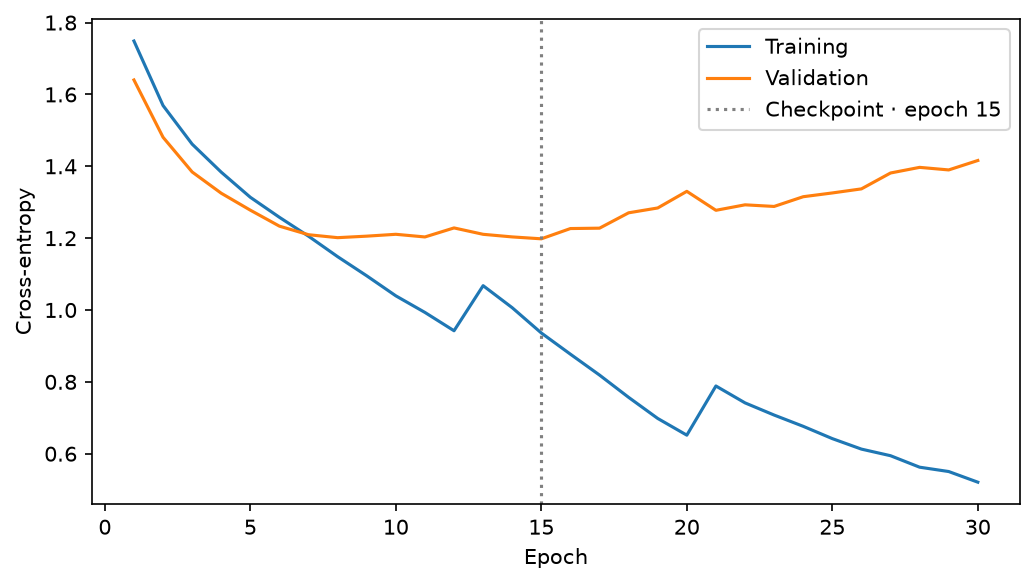

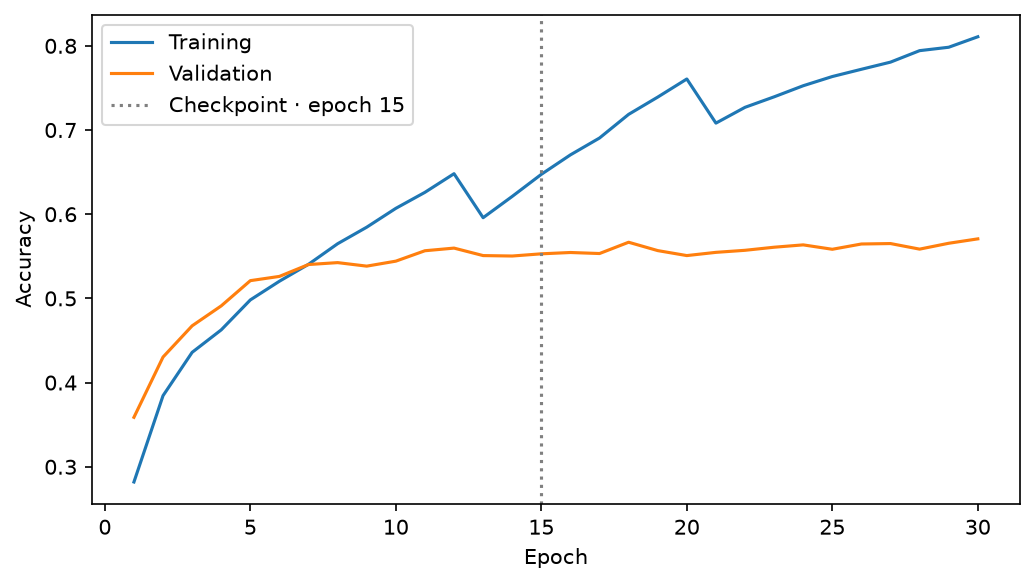

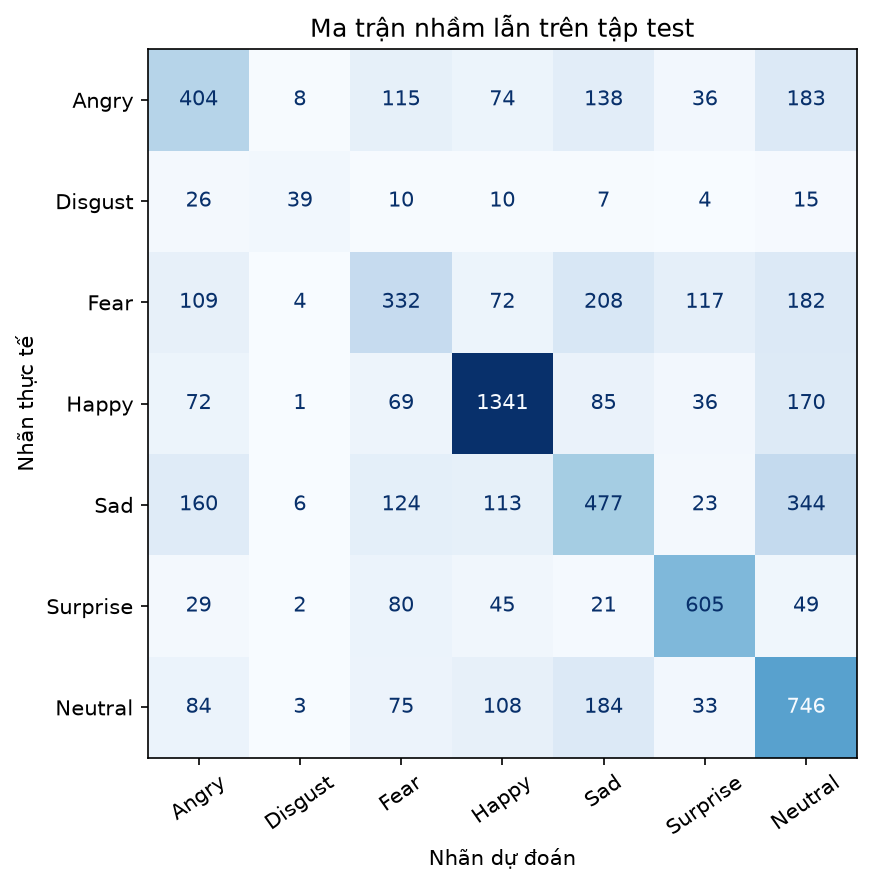

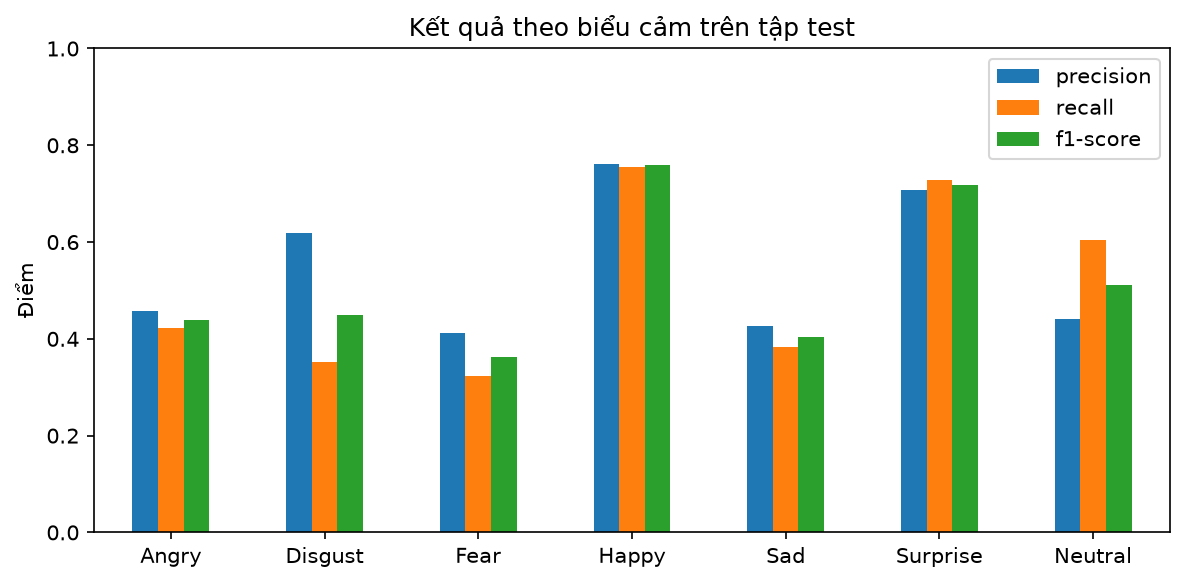

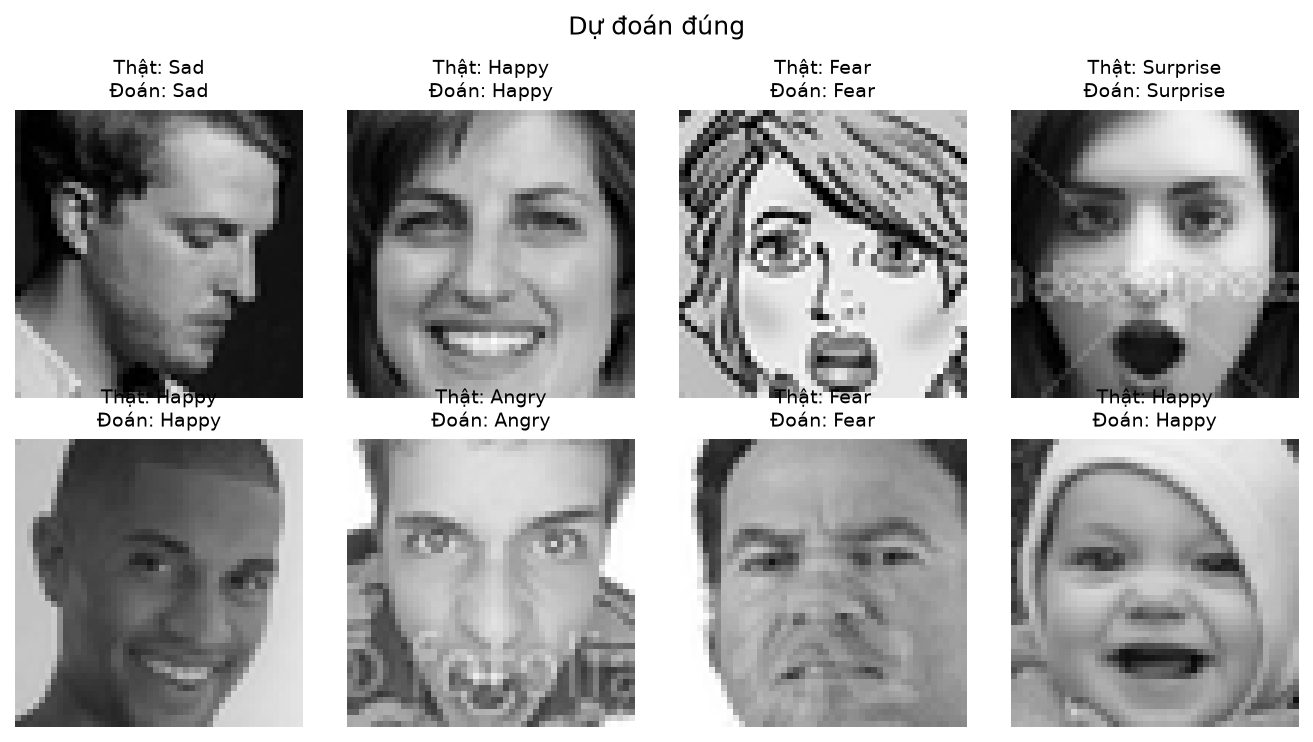

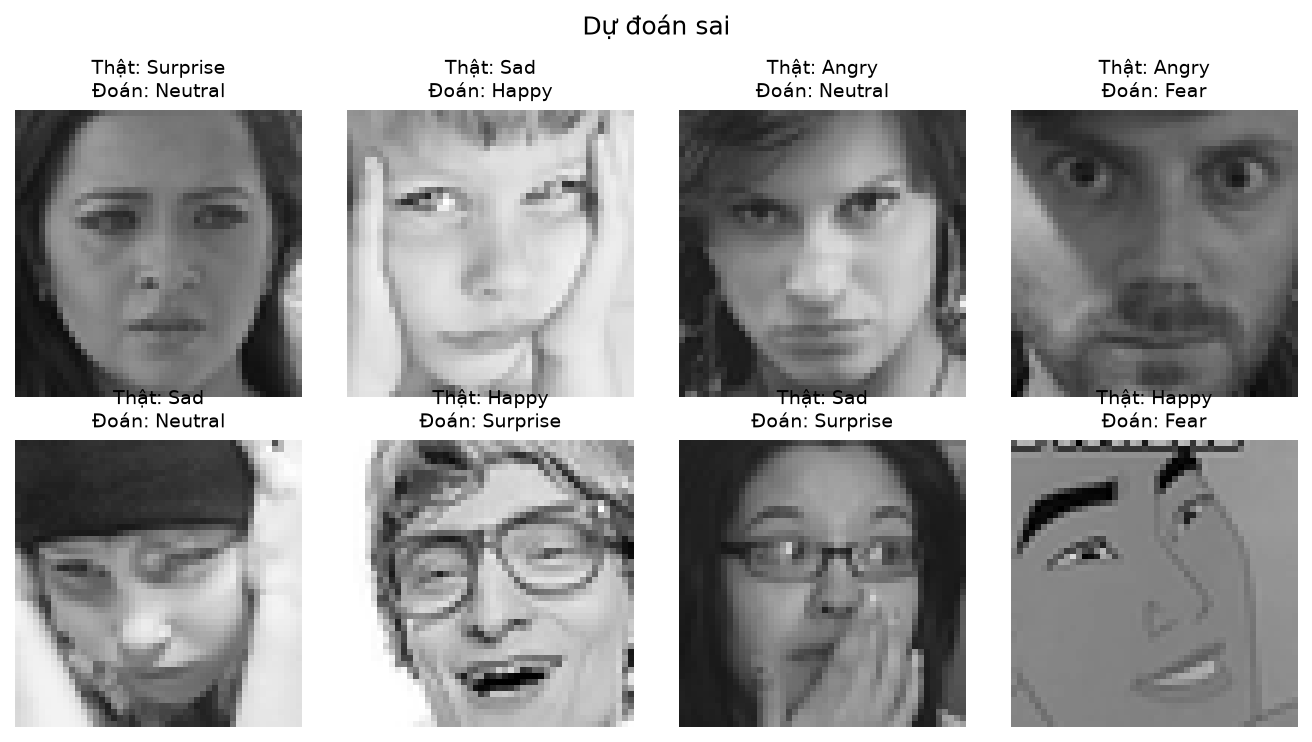

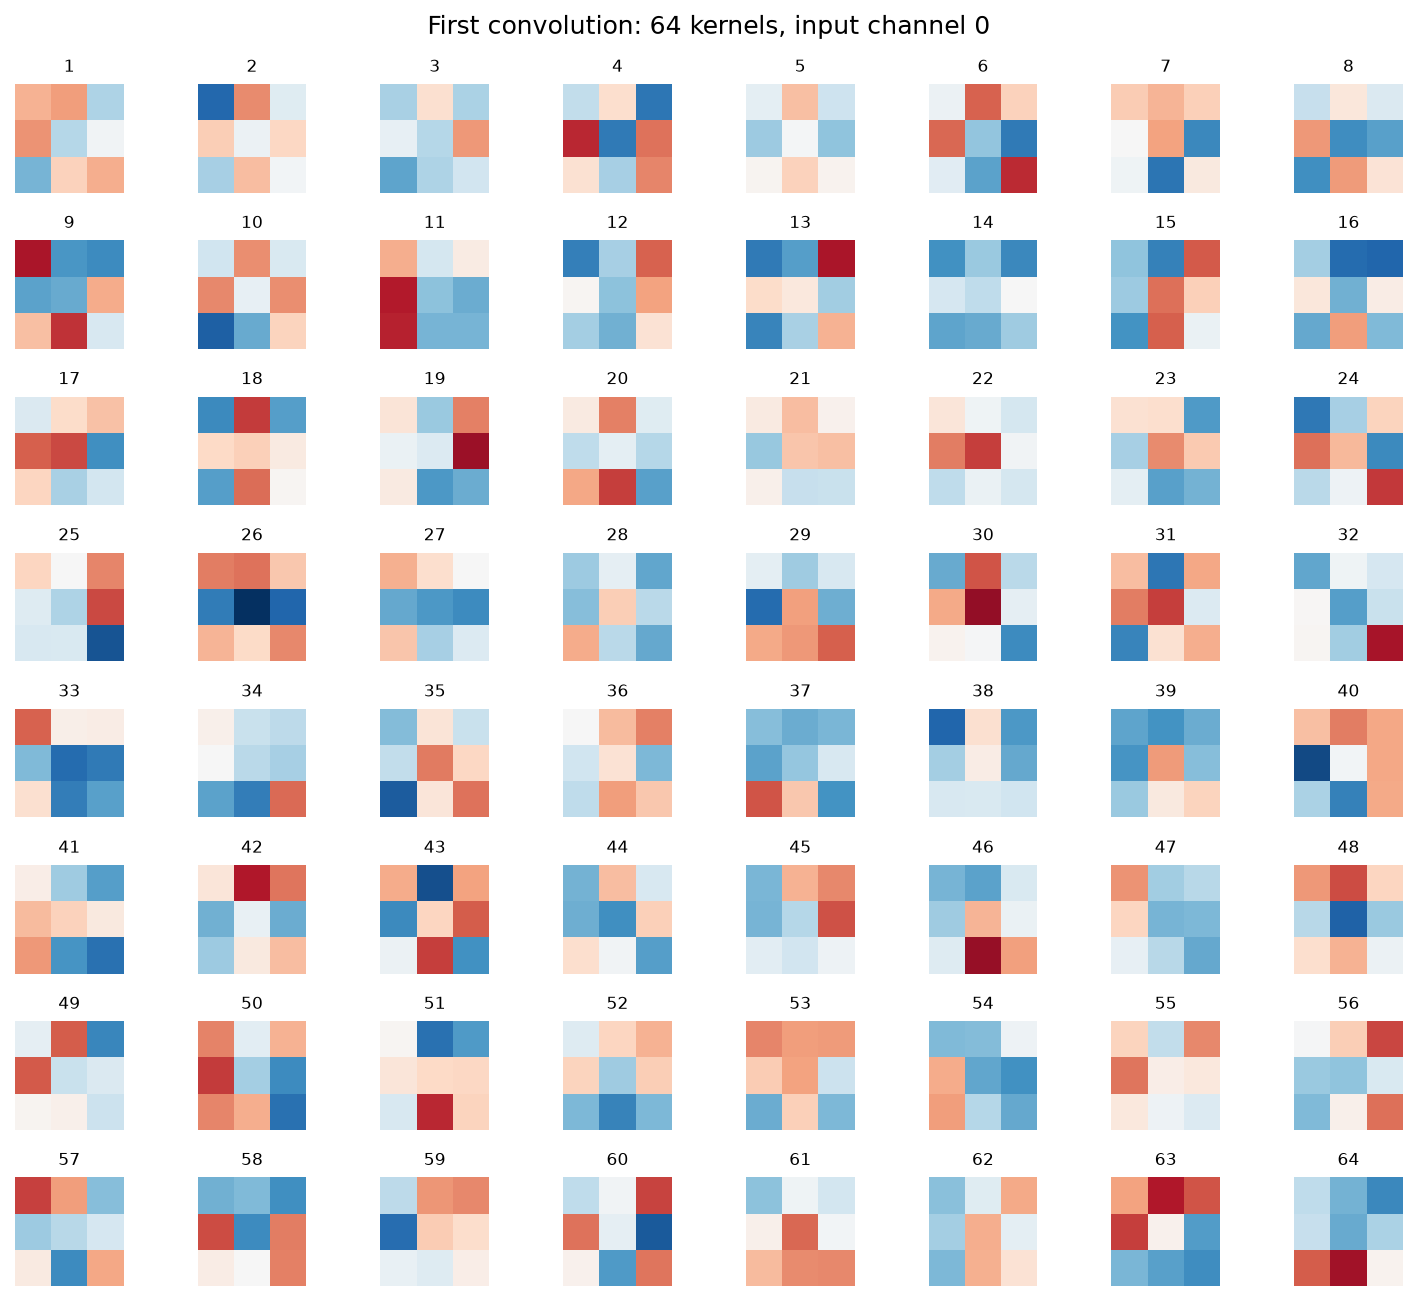

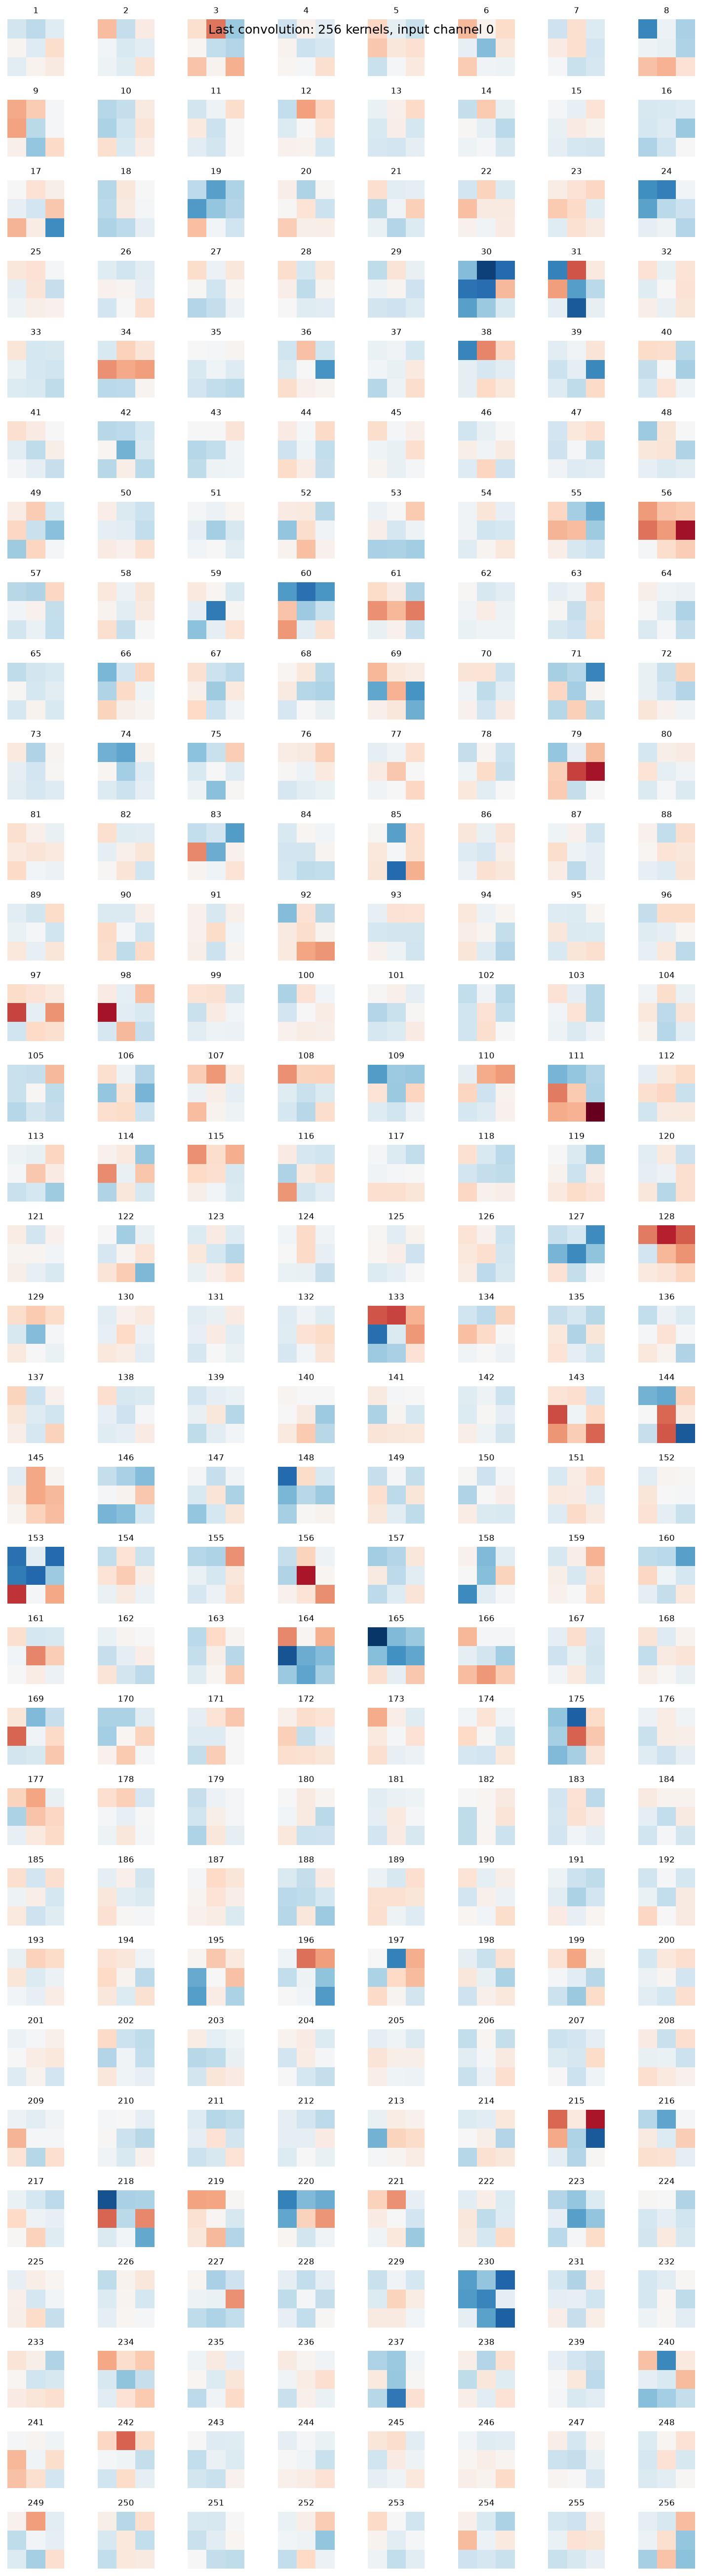

In [5]:
if run is not None:
    for name in ("loss", "accuracy", "confusion_matrix", "per_class", "correct", "incorrect",
                 "conv1_filters", "last_conv_filters"):
        path = run / f"{name}.png"
        if path.is_file():
            display(Image(filename=str(path), width=800))
        else:
            print("Chưa có hình:", path.name, "— chạy đánh giá để tạo.")

## 6 Bảng tổng hợp thí nghiệm
Điền từ `training.json` và `evaluation.json` sau khi chạy, ghi rõ cấu hình, thời gian và số tham số.
So sánh cùng split và seed; mỗi thí nghiệm thay một yếu tố. Thảo luận Dropout/kiến trúc như một thay đổi
tổng thể ở EXP002, không quy chênh lệch điểm riêng cho một thành phần chưa kiểm chứng.

| Experiment | Thay đổi | Best val loss | Val accuracy tại best | Test macro F1 | Parameters | Seconds |
|---|---|---|---|---|---|---|
| EXP001 | Baseline | | | | | |
| EXP002 | CNN + MLP từ mẫu MNIST | 1.198144 | 55.29% | 0.5200 | 5,355,015 | Resume 2190.980 giây |